
0: 288x320 1 OpticDisk, 2 Maculas, 99.2ms
Speed: 5.0ms preprocess, 99.2ms inference, 1.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.


Angle α: -5.856013585428958 degrees


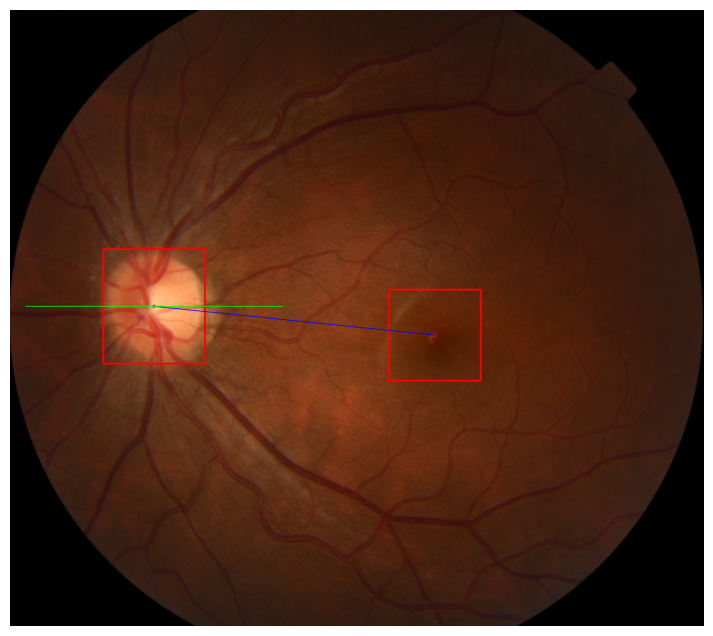

In [17]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import os
import numpy as np
import torch

# Load a pretrained YOLOv8n model
model = YOLO('best.pt')
image_path = 'D:/xieshiAI/class2/class2/shang/OS/OSyirubingshang(+).jpg'
# image_files = [os.path.join(image_folder, f) for f in os.listdir(image_folder) if f.endswith(('.jpg', '.png'))]
image = cv2.imread(image_path)

if image is None:
    print("Image not found!")
else:
    results = model.predict(image, imgsz=320, conf=0.2)[0]
    boxes = results.boxes.boxes
    unique_classes = boxes[:, -1].unique()
    best_indices = []
    for cls in unique_classes:
        # 获取当前类别的所有边界框
        class_mask = (boxes[:, -1] == cls)
        class_boxes = boxes[class_mask]
        # 找出置信度最高的边界框索引
        best_index = torch.argmax(class_boxes[:, -2])
        best_indices.append(class_mask.nonzero()[best_index].item())
    # 使用找到的索引来获取边界框
    boxes = boxes[best_indices]
    centers = []
    for bbox in boxes:
        x1, y1, x2, y2, conf, cls_id = bbox
        center_x = int((x1 + x2) / 2)
        center_y = int((y1 + y2) / 2)
        centers.append({'center': (center_x, center_y), 'cls_id': cls_id})
        # 画出边界框
        cv2.rectangle(image, (int(x1), int(y1)), (int(x2), int(y2)), (0, 0, 255), 5)
        # 标记中心点
        cv2.circle(image, (center_x, center_y), 5, (0, 0, 255), 2)
        
    for item in centers:
        if item['cls_id'] == 0:  # cls_id为0是试盘
            optic_disk_center = np.array(item['center'])
        elif item['cls_id'] == 1:  # cls_id为1是黄斑
            macula_center = np.array(item['center'])
    
    cv2.line(image, tuple(optic_disk_center), tuple(macula_center), (255, 0, 0), 2) # Line connecting centers

    # Draw horizontal line at optic disk center
    line_length = 1000
    cv2.line(image, (optic_disk_center[0] - line_length // 2, optic_disk_center[1]), 
             (optic_disk_center[0] + line_length // 2, optic_disk_center[1]), (0, 255, 0), 2)

    # Calculate the angle α
    vector_center_to_center = macula_center - optic_disk_center
    angle_radians = np.arctan2(-vector_center_to_center[1], vector_center_to_center[0])  # Note the negative sign due to y-axis direction
    angle_degrees = np.degrees(angle_radians)

    angle_degrees = np.abs(angle_degrees)  # 转换为正值
    if angle_degrees > 90:
        angle_degrees = 180 - angle_degrees  # 转换为锐角
    
    if macula_center[1] > optic_disk_center[1]:
        angle_degrees = -angle_degrees
        
    print(f"Angle α: {angle_degrees} degrees")
    
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10, 8))
    plt.imshow(image_rgb)
    plt.axis('off')
    plt.show()

In [6]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import os
import numpy as np
import torch
import pandas as pd
from pathlib import Path

# Load a pretrained YOLOv8n model
model = YOLO('best.pt')
# 设定文件夹路径
folder_path = 'D:/xieshiAI/class2/class2/xie/OD'
# 创建一个空列表来存储结果
results_list = []

for image_file in Path(folder_path).glob('*.jpg'):
    image = cv2.imread(str(image_file))
    if image is None:
         print(f"Image not found: {image_file}")
    else:
        results = model.predict(image, imgsz=320, conf=0.2)[0]
        boxes = results.boxes.boxes
        unique_classes = boxes[:, -1].unique()
        best_indices = []
        for cls in unique_classes:
            # 获取当前类别的所有边界框
            class_mask = (boxes[:, -1] == cls)
            class_boxes = boxes[class_mask]
            # 找出置信度最高的边界框索引
            best_index = torch.argmax(class_boxes[:, -2])
            best_indices.append(class_mask.nonzero()[best_index].item())
        # 使用找到的索引来获取边界框
        boxes = boxes[best_indices]
        centers = []
        for bbox in boxes:
            x1, y1, x2, y2, conf, cls_id = bbox
            center_x = int((x1 + x2) / 2)
            center_y = int((y1 + y2) / 2)
            centers.append({'center': (center_x, center_y), 'cls_id': cls_id})
            # 画出边界框
            cv2.rectangle(image, (int(x1), int(y1)), (int(x2), int(y2)), (0, 0, 255), 5)
            # 标记中心点
            cv2.circle(image, (center_x, center_y), 5, (0, 0, 255), 2)

        for item in centers:
            if item['cls_id'] == 0:  # cls_id为0是试盘
                optic_disk_center = np.array(item['center'])
            elif item['cls_id'] == 1:  # cls_id为1是黄斑
                macula_center = np.array(item['center'])

        cv2.line(image, tuple(optic_disk_center), tuple(macula_center), (255, 0, 0), 2) # Line connecting centers

        # Draw horizontal line at optic disk center
        line_length = 1000
        cv2.line(image, (optic_disk_center[0] - line_length // 2, optic_disk_center[1]), 
                 (optic_disk_center[0] + line_length // 2, optic_disk_center[1]), (0, 255, 0), 2)

        # Calculate the angle α
        vector_center_to_center = macula_center - optic_disk_center
        angle_radians = np.arctan2(-vector_center_to_center[1], vector_center_to_center[0])  # Note the negative sign due to y-axis direction
        angle_degrees = np.degrees(angle_radians)

        angle_degrees = np.abs(angle_degrees)  # 转换为正值
        if angle_degrees > 90:
            angle_degrees = 180 - angle_degrees  # 转换为锐角

        if macula_center[1] > optic_disk_center[1]:
            angle_degrees = -angle_degrees

        results_list.append({'Image Name': image_file.name, 'Angle α (degrees)': angle_degrees})
#         image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
#         plt.figure(figsize=(10, 8))
#         plt.imshow(image_rgb)
#         plt.axis('off')
#         plt.show()

# 创建一个 pandas DataFrame
results_df = pd.DataFrame(results_list)
# 将 DataFrame 保存到 Excel 文件
excel_path = 'angles_xie_OD.xlsx'
results_df.to_excel(excel_path, index=False)
print(f"Results saved to {excel_path}")


0: 288x320 1 OpticDisk, 1 Macula, 51.8ms
Speed: 3.8ms preprocess, 51.8ms inference, 1.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 1 Macula, 51.5ms
Speed: 2.0ms preprocess, 51.5ms inference, 1.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 1 Macula, 54.7ms
Speed: 0.0ms preprocess, 54.7ms inference, 0.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 2 Maculas, 46.3ms
Speed: 0.0ms preprocess, 46.3ms inference, 1.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 2 Maculas, 51.2ms
Speed: 1.9ms preprocess, 51.2ms inference, 0.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxe

WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 2 Maculas, 48.0ms
Speed: 0.0ms preprocess, 48.0ms inference, 0.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 1 Macula, 48.0ms
Speed: 4.0ms preprocess, 48.0ms inference, 0.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 2 Maculas, 44.0ms
Speed: 0.0ms preprocess, 44.0ms inference, 4.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 2 Maculas, 44.0ms
Speed: 0.0ms preprocess, 44.0ms inference, 0.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 2 Maculas, 52.0ms
Speed: 4.0ms preprocess, 52.0ms inference, 0.0ms postprocess per image at shap


0: 320x320 1 OpticDisk, 2 Maculas, 48.0ms
Speed: 4.0ms preprocess, 48.0ms inference, 0.0ms postprocess per image at shape (1, 3, 320, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 320x320 1 OpticDisk, 2 Maculas, 56.0ms
Speed: 0.0ms preprocess, 56.0ms inference, 0.0ms postprocess per image at shape (1, 3, 320, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 1 Macula, 48.0ms
Speed: 0.0ms preprocess, 48.0ms inference, 0.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 2 Maculas, 44.0ms
Speed: 0.0ms preprocess, 44.0ms inference, 0.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 320x320 1 OpticDisk, 1 Macula, 48.0ms
Speed: 0.0ms preprocess, 48.0ms inference, 0.0ms postprocess per image at shape (1, 3, 320, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Box

WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 2 Maculas, 52.0ms
Speed: 0.0ms preprocess, 52.0ms inference, 0.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 1 Macula, 54.7ms
Speed: 4.0ms preprocess, 54.7ms inference, 1.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 2 Maculas, 48.5ms
Speed: 0.0ms preprocess, 48.5ms inference, 4.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 2 Maculas, 48.0ms
Speed: 0.0ms preprocess, 48.0ms inference, 0.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 3 Maculas, 48.0ms
Speed: 4.0ms preprocess, 48.0ms inference, 4.0ms postprocess per image at shap


0: 320x320 1 OpticDisk, 1 Macula, 58.1ms
Speed: 0.0ms preprocess, 58.1ms inference, 1.0ms postprocess per image at shape (1, 3, 320, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 2 Maculas, 43.7ms
Speed: 1.0ms preprocess, 43.7ms inference, 1.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 1 Macula, 48.4ms
Speed: 0.0ms preprocess, 48.4ms inference, 1.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 1 Macula, 51.3ms
Speed: 0.0ms preprocess, 51.3ms inference, 0.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 2 Maculas, 49.7ms
Speed: 0.0ms preprocess, 49.7ms inference, 1.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxe

WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 2 Maculas, 45.2ms
Speed: 2.0ms preprocess, 45.2ms inference, 1.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 1 Macula, 54.4ms
Speed: 4.0ms preprocess, 54.4ms inference, 0.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 2 Maculas, 56.6ms
Speed: 0.0ms preprocess, 56.6ms inference, 0.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 1 Macula, 54.0ms
Speed: 1.1ms preprocess, 54.0ms inference, 0.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 1 Macula, 52.9ms
Speed: 0.0ms preprocess, 52.9ms inference, 1.0ms postprocess per image at shape 

Speed: 4.0ms preprocess, 54.1ms inference, 0.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 2 Maculas, 55.4ms
Speed: 1.9ms preprocess, 55.4ms inference, 1.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 1 Macula, 66.2ms
Speed: 5.1ms preprocess, 66.2ms inference, 0.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 2 Maculas, 68.3ms
Speed: 2.0ms preprocess, 68.3ms inference, 0.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk, 2 Maculas, 54.9ms
Speed: 1.0ms preprocess, 54.9ms inference, 1.0ms postprocess per image at shape (1, 3, 288, 320)
WARNING  'Boxes.boxes' is deprecated. Use 'Boxes.data' instead.

0: 288x320 1 OpticDisk,

Results saved to angles_xie_OD.xlsx


In [29]:
# 逻辑回归-二分类
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_excel('angles_2(weifanzhuan) .xlsx')
# 提取角度和类别列
angles = np.abs(df['Angle'].values)
labels = df['class'].values
# 特征工程：将角度转换为正弦和余弦值
X = np.column_stack((np.sin(np.radians(angles)), np.cos(np.radians(angles))))
y = labels

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 训练模型
model = LogisticRegression()
model.fit(X_train, y_train)

# 使用测试集进行评估
accuracy = model.score(X_test, y_test)

print(f'Model accuracy on test set: {accuracy * 100:.2f}%')

# 预测新的角度
new_angle = 40  # 你要预测的角度
new_features = np.array([[np.sin(np.radians(new_angle)), np.cos(np.radians(new_angle))]])

# 进行分类预测
predicted_class = model.predict(new_features)
predicted_probabilities = model.predict_proba(new_features)

print(predicted_class)
print(predicted_probabilities)

Model accuracy on test set: 63.37%
[0]
[[0.80124183 0.19875817]]


In [15]:
#逻辑回归-三分类
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_excel('angles_3(weifanzhuan).xlsx')
# 提取角度和类别列
angles = df['Angle'].values
labels = df['class'].values
# 特征工程：将角度转换为正弦和余弦值
X = np.column_stack((np.sin(np.radians(angles)), np.cos(np.radians(angles))))
y = labels

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 训练模型
model = OneVsRestClassifier(LogisticRegression())
model.fit(X_train, y_train)

# 使用测试集进行评估
accuracy = model.score(X_test, y_test)

print(f'Model accuracy on test set: {accuracy * 100:.2f}%')

# 预测新的角度
new_angle = 20  # 你要预测的角度
new_features = np.array([[np.sin(np.radians(new_angle)), np.cos(np.radians(new_angle))]])

# 进行分类预测
predicted_class = model.predict(new_features)
predicted_probabilities = model.predict_proba(new_features)

print(predicted_class)
print(predicted_probabilities)

Model accuracy on test set: 65.35%
[2]
[[    0.27352     0.09015     0.63633]]


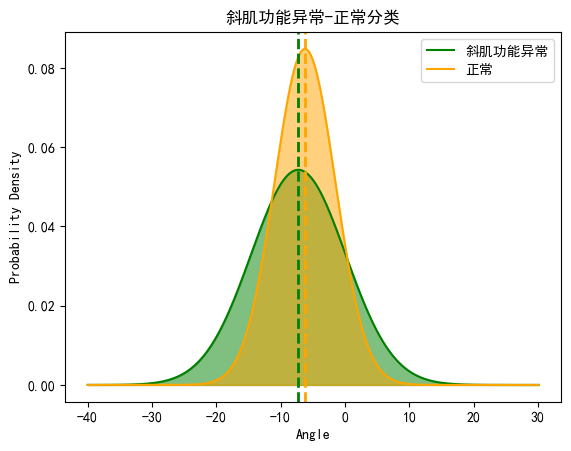

In [100]:
# 贝叶斯分类-二分类
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import pandas as pd
plt.rcParams['font.sans-serif']=['SimHei'] #用来正常显示中文标签
plt.rcParams['axes.unicode_minus']=False #用来正常显示负号

df = pd.read_excel('angles_2(weifanzhuan) .xlsx')
# 提取角度和类别列
angles = df['Angle'].values
labels = df['class'].values
# 分离每个类别的数据
angles_xieshi = angles[labels == 0]
angles_healthy = angles[labels == 1]

# 为每个类别计算均值和标准差
mu_xieshi, sigma_xieshi = np.mean(angles_xieshi), np.std(angles_xieshi)
mu_healthy, sigma_healthy = np.mean(angles_healthy), np.std(angles_healthy)

# 为绘图定义一个角度的范围
angle_values = np.linspace(-40, np.max(angles), 1000)

# 计算高斯概率密度函数的值
pdf_xieshi = norm.pdf(angle_values, mu_xieshi, sigma_xieshi)
pdf_healthy = norm.pdf(angle_values, mu_healthy, sigma_healthy)

# 绘制两个类别的概率分布
plt.plot(angle_values, pdf_xieshi, label='斜肌功能异常', color='green')
plt.fill_between(angle_values, pdf_xieshi, color='green', alpha=0.5)
plt.plot(angle_values, pdf_healthy, label='正常', color='orange')
plt.fill_between(angle_values, pdf_healthy, color='orange', alpha=0.5)

# # 标注均值位置
plt.axvline(mu_xieshi, color='green', linestyle='dashed', linewidth=2)
plt.axvline(mu_healthy, color='orange', linestyle='dashed', linewidth=2)

# 添加图例和标题
plt.legend()
plt.title('斜肌功能异常-正常分类')
plt.xlabel('Angle')
plt.ylabel('Probability Density')

# 显示图表
plt.show()

In [238]:
x = -5
p_x_given_xieshi = norm.pdf(x, mu_xieshi, sigma_xieshi)
p_x_given_healthy = norm.pdf(x, mu_healthy, sigma_healthy)

# 计算属于斜肌功能异常类别的概率
probability_xieshi = p_x_given_xieshi / (p_x_given_xieshi + p_x_given_healthy)

print("在角度 {:.3f} 度时，属于斜肌功能异常类别的概率为 {:.2%}".format(x, probability_xieshi))

在角度 -5.000 度时，属于斜肌功能异常类别的概率为 38.71%


在角度为-17.286以及 6.278 度时，属于斜肌功能异常类别的概率为 80.00%
在角度为-18.350以及 7.341 度时，属于斜肌功能异常类别的概率为 85.00%
在角度为-19.635以及 8.627 度时，属于斜肌功能异常类别的概率为 90.00%
在角度为-21.500以及 10.490 度时，属于斜肌功能异常类别的概率为 95.00%

In [237]:
x = -5
p_x_given_xieshi = norm.pdf(x, mu_xieshi, sigma_xieshi)
p_x_given_healthy = norm.pdf(x, mu_healthy, sigma_healthy)

probability_healthy = p_x_given_healthy / (p_x_given_xieshi + p_x_given_healthy)

print("在角度 {:.3f} 度时，属于正常类别的概率为 {:.2%}".format(x, probability_healthy))

在角度 -5.000 度时，属于正常类别的概率为 61.29%


In [103]:
import numpy as np
from scipy.stats import norm
from scipy.integrate import quad

# 定义两个正态分布
dist_xieshi = norm(mu_xieshi, sigma_xieshi)
dist_healthy = norm(mu_healthy, sigma_healthy)

# 定义积分函数，计算两个分布的重叠面积
def overlap_integral(x):
    return np.minimum(dist_xieshi.pdf(x), dist_healthy.pdf(x))

# 积分范围，从最小的均值减去三个标准差到最大的均值加上三个标准差
range_min = min(mu_xieshi - 3*sigma_xieshi, mu_healthy - 3*sigma_healthy)
range_max = max(mu_xieshi + 3*sigma_xieshi, mu_healthy + 3*sigma_healthy)

# 计算重叠区域的面积
overlap_area, _ = quad(overlap_integral, range_min, range_max)

# 计算斜肌功能异常的总面积
total_area_xieshi, _ = quad(lambda x: dist_xieshi.pdf(x), range_min, range_max)

# 计算正常类别的总面积
total_area_healthy, _ = quad(lambda x: dist_healthy.pdf(x), range_min, range_max)

# 计算非重叠区域的面积
non_overlap_xieshi = total_area_xieshi - overlap_area
non_overlap_healthy = total_area_healthy - overlap_area

# 计算各部分的占比（相对于总面积）
total_area = non_overlap_xieshi + overlap_area + non_overlap_healthy

non_overlap_xieshi_percentage = non_overlap_xieshi / total_area * 100
overlap_percentage = overlap_area / total_area * 100
non_overlap_healthy_percentage = non_overlap_healthy / total_area * 100

# 打印结果
print("斜肌功能异常非重叠区域占比: {:.2f}%".format(non_overlap_xieshi_percentage))
print("重叠区域占比: {:.2f}%".format(overlap_percentage))
print("正常类别非重叠区域占比: {:.2f}%".format(non_overlap_healthy_percentage))
print("总和: {:.2f}%".format(non_overlap_xieshi_percentage + overlap_percentage + non_overlap_healthy_percentage))
print("斜肌功能异常均值：{:.2f}".format(mu_xieshi))
print("斜肌功能异常方差：{:.2f}".format(sigma_xieshi))
print("正常组均值：{:.2f}".format(mu_healthy))
print("正常组方差：{:.2f}".format(sigma_healthy))

斜肌功能异常非重叠区域占比: 17.85%
重叠区域占比: 64.08%
正常类别非重叠区域占比: 18.07%
总和: 100.00%
斜肌功能异常均值：-7.26
斜肌功能异常方差：7.35
正常组均值：-6.22
正常组方差：4.71


In [115]:
import pandas as pd
from scipy.stats import ttest_ind
import numpy as np

# 读取数据
df = pd.read_excel('angles_2(weifanzhuan) .xlsx')

# 提取角度和类别列
angles = df['Angle'].values
labels = df['class'].values

# 分离每个类别的数据
angles_xieshi = angles[labels == 0]
angles_healthy = angles[labels == 1]

# 计算均值和标准差
mu_xieshi, sigma_xieshi = np.mean(angles_xieshi), np.std(angles_xieshi)
mu_healthy, sigma_healthy = np.mean(angles_healthy), np.std(angles_healthy)

# 打印均值和标准差
print(f"斜肌功能异常均值: {mu_xieshi:.2f}, 标准差: {sigma_xieshi:.2f}")
print(f"正常类别均值: {mu_healthy:.2f}, 标准差: {sigma_healthy:.2f}")

# 进行独立样本t检验
t_stat, p_value = ttest_ind(angles_xieshi, angles_healthy)

# 打印t统计量和p值
print(f"T统计量: {t_stat}, p值: {p_value}")
# t值: t值为7.015835989811465，表明两组数据的均值之间存在显著差异。t值越大，说明两个样本均值之间的差异越大。
# p值: p值为4.1958892567135305e-12（非常接近于0），远小于常用的显著性水平（例如0.05或0.01）。这表示在显著性水平为0.05或0.01的情况下，我们可以拒绝原假设，即认为斜视组和正常组的角度分布存在显著差异。

斜肌功能异常均值: -7.26, 标准差: 7.35
正常类别均值: -6.22, 标准差: 4.71
T统计量: -2.7243808670842515, p值: 0.006554004690853078


In [116]:
import pandas as pd
from scipy.stats import mannwhitneyu, ks_2samp, levene

df = pd.read_excel('angles_2(weifanzhuan) .xlsx')
# 提取角度和类别列
angles = df['Angle'].values
labels = df['class'].values
# 分离每个类别的数据
angles_xieshi = angles[labels == 0]
angles_healthy = angles[labels == 1]

# 进行 Mann-Whitney U 检验
u_stat, p_value_u = mannwhitneyu(angles_xieshi, angles_healthy)

# 进行 Kolmogorov-Smirnov 检验
ks_stat, p_value_ks = ks_2samp(angles_xieshi, angles_healthy)

# 进行 Levene's 检验
levene_stat, p_value_levene = levene(angles_xieshi, angles_healthy)

In [117]:
u_stat, p_value_u

(102606.5, 0.00020005060456075108)

In [118]:
ks_stat, p_value_ks

(0.14083503140382211, 0.0001445581877647069)

In [119]:
levene_stat, p_value_levene

(37.75134095934838, 1.1565949187293017e-09)

In [1]:
import gradio as gr
from ultralytics import YOLO
import cv2
import numpy as np
import torch

# 载入预训练的 YOLO 模型
model = YOLO('best.pt')

def process_image(image):
    image = cv2.cvtColor(np.array(image), cv2.COLOR_RGB2BGR)
    if image is None:
        return "Image not found!", None

    results = model.predict(image, imgsz=320, conf=0.2)[0]
    boxes = results.boxes.boxes
    unique_classes = boxes[:, -1].unique()
    best_indices = []
    for cls in unique_classes:
        class_mask = (boxes[:, -1] == cls)
        class_boxes = boxes[class_mask]
        best_index = torch.argmax(class_boxes[:, -2])
        best_indices.append(class_mask.nonzero()[best_index].item())
    boxes = boxes[best_indices]
    centers = []
    for bbox in boxes:
        x1, y1, x2, y2, conf, cls_id = bbox
        center_x = int((x1 + x2) / 2)
        center_y = int((y1 + y2) / 2)
        centers.append({'center': (center_x, center_y), 'cls_id': cls_id})
        cv2.rectangle(image, (int(x1), int(y1)), (int(x2), int(y2)), (0, 0, 255), 5)
        cv2.circle(image, (center_x, center_y), 5, (0, 0, 255), 2)

    optic_disk_center = np.array([0, 0])
    macula_center = np.array([0, 0])
    for item in centers:
        if item['cls_id'] == 0:
            optic_disk_center = np.array(item['center'])
        elif item['cls_id'] == 1:
            macula_center = np.array(item['center'])
    
    cv2.line(image, tuple(optic_disk_center), tuple(macula_center), (255, 0, 0), 2)
    line_length = 1000
    cv2.line(image, (optic_disk_center[0] - line_length // 2, optic_disk_center[1]), 
             (optic_disk_center[0] + line_length // 2, optic_disk_center[1]), (0, 255, 0), 2)

    vector_center_to_center = macula_center - optic_disk_center
    angle_radians = np.arctan2(-vector_center_to_center[1], vector_center_to_center[0])
    angle_degrees = np.degrees(angle_radians)
    angle_degrees = np.abs(angle_degrees)
    if angle_degrees > 90:
        angle_degrees = 180 - angle_degrees
    if macula_center[1] > optic_disk_center[1]:
        angle_degrees = -angle_degrees

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    return image, f"Angle α: {angle_degrees} degrees"

demo = gr.Interface(fn=process_image,
                     inputs=gr.Image(),
                     outputs=["image", "text"],
                     title="斜视检测",
                     description="Upload an image to detect objects and calculate angles.")
    
if __name__ == "__main__":
    app, local_url, share_url = demo.launch(share=True)

ModuleNotFoundError: No module named 'typing_extensions'

In [2]:
!pip install typing-extensions

Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://mirrors.aliyun.com/pypi/simple/



[notice] A new release of pip is available: 23.3.2 -> 24.2
[notice] To update, run: python.exe -m pip install --upgrade pip
